**Nombre:** Kevin Abraham Fernandez Sanchez

**Matrícula:** 25041246

**Materia:** Probabilidad y Estadística

**Caso 21:** Distribución de probabilidad normal

**Herramienta de cálculo:** Python (Google Colab)


# Distribución de probabilidad normal

# Objetivo

Calcular probabilidades, valor esperado y variabilidad de datos de varibles aleatorias con comportamiento de distribución  normal.


# Descripción

- Se cargan librerías adecuadas
- Se cargan funciones adecuadas
- Se describen ejercicios extraídos de literatura de contexos diversos con caraterísticas de distribuciones normales.
- Se calculan probabilidades
- Se calculan valores esperados y variabilidad de los datos,
- Se calculan números aleatorios
- Se calculan valores de variable aleatoria $x$ a partir de probabilidades específicas. PENDIENTE ESTE ULTIMO PUNTO


# Fundamento teórico

La distribución continua de probabilidad más importante en todo el campo de la estadística es la distribución normal. Su gráfica, que se denomina curva normal, es la curva con forma de campana .

La distribución normal a menudo se denomina distribución Gaussiana, en honor de Karl Friedrich Gauss (1777-1855), quien también derivó su ecuación a partir de un estudio de errores en mediciones repetidas de la misma cantidad [@walpole2012].

## Fórmula de densidad

$$
f(x) =\frac{1}{\sigma \cdot \sqrt{2 \cdot \pi}}\cdot e
^{\frac{-1}{2}\cdot ( \frac {x - \mu}{\sigma}) ^2}
$$

En donde: $π=3.14159$ y $e=2.71828$.

## Función de Distribución Acumulativa (CDF):

La CDF es una función que proporciona la probabilidad acumulativa de que una variable aleatoria sea menor o igual a un valor específico. Se denota como:
$$
F(x) = \int_{-∞}^{x}f(x)dx
$$

donde $f(x)$ es la PDF.

## Valor Esperado (Media)

El valor esperado de una variable aleatoria continua se calcula como el promedio ponderado de todos los valores posibles, donde el peso es dado por la PDF. Matemáticamente, se expresa como
$$
\mu_{x} = VE(x) = \int_{-\infty}^{\infty}x\cdot f(x)dx
$$

## Varianza y Desviación Estándar:

La varianza y la desviación estándar miden la dispersión de una variable aleatoria continua. La varianza se calcula como:

$$
varianza = \sigma^2=V(x)=\int_{-\infty}^{\infty}(x - \mu)^2\cdot f(x) dx
$$
, donde $\mu$ es la media, y la desviación estándar es la raíz cuadrada de la varianza

$$
\sigma = \sqrt{\sigma^2}
$$

## Funciones de python

En python se pueden utilizar las siguientes funciones para tratar con una distribución normal:

- *norm.rvs()* para calcular números aleatorios.
- *norm.pdf()* para calcular la densidad.
- *norm.cdf()* para calcular la probabilidad acumulada.
- *norm.ppf()* para calcular el valor de la a partir de una probabilidad, es la función inversa de *cdf()*.



# Desarrollo


## Cargar librerías

In [1]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

## Cargar funciones

In [2]:
# Densidad normal
def f_x_normal(x, media, desv_std):
  # Calcular la PDF de la variable aleatoria continua
  fx = 1 / (desv_std * np.sqrt(2 * np.pi)) * np.exp(-(x - media)**2 / (2 * desv_std ** 2))
  return fx

# Función para visualizar la densidad de probabilidad de una distribución normal
def f_visualizar_dens_normal(valores):
    # Se calcula la media de los valores
    media = np.mean(valores)

    # Se calcula la desviacióne st´dnar de los valores
    desv_std = np.std(valores)

    # Crear un rango de valores para la crear una densidad
    x = np.linspace(media - 3 * desv_std, media + 3 * desv_std, 1000)

    # Calcular la PDF de la distribución normal
    pdf = 1 / (desv_std * np.sqrt(2 * np.pi)) * np.exp(-(x - media)**2 / (2 * desv_std **2))

    # Visualizar la PDF
    plt.plot(x, pdf, label='Normal:(media:{}; ds:{})'.format(np.round(media, 2), np.round(desv_std, 2)))
    plt.title('Función de Densidad de Probabilidad (PDF) - Distribución Normal')
    plt.xlabel('Valor de x')
    plt.ylabel('Densidad de Probabilidad')
    plt.legend()
    # plt.grid(True)
    plt.show()

def f_visualizar_dens_area_normal(valores, a, b, prob=0, v_color = 'red'):
    # Se calcula la media de los valores
    media = np.mean(valores)

    # Se calcula la desviacióne estándar de los valores
    desv_std = np.std(valores)

    # Crear un rango de valores para la PDF
    x = np.linspace(media - 3 * desv_std, media + 3 * desv_std, 1000)

    # Calcular la PDF de la distribución normal
    pdf = 1 / (desv_std * np.sqrt(2 * np.pi)) * np.exp(-(x - media)**2 / (2 * desv_std ** 2))

    # LA probailidad
    prob  = norm.cdf(b, media, desv_std) - norm.cdf(a, media, desv_std)
    # Visualizar la PDF
    plt.plot(x, pdf, label='Normal:(me:{}; ds:{})'.format(np.round(media, 2), np.round(desv_std, 2)))
    if prob == 0:
      plt.fill_between(x, 0, pdf, where=(x >= a) & (x <= b), alpha=0.3, color=v_color, label='Área bajo la curva')
    else:
      plt.fill_between(x, 0, pdf, where=(x >= a) & (x <= b), alpha=0.3, color=v_color, label='Área '+str(a) + "-"+str(b)+"="+str(np.round(prob * 100, 2))+"%")

    plt.title('Función de Densidad de Probabilidad (PDF) - Distribución Normal')
    plt.xlabel('Valor de x')
    plt.ylabel('Densidad de Probabilidad')
    plt.legend(loc='upper right')
    # plt.grid(True)
    plt.show()

def f_visualizar_frecuencia(frecuencia):
  # Crear gráfico de barras
  plt.bar(frecuencia.index, frecuencia)

  # Agregar etiquetas y título
  plt.xlabel('Variable')
  plt.ylabel('Frecuencia')
  plt.title('Frecuencia en los Datos')

  # Mostrar el gráfico
  plt.show()

def f_visualizar_VE_desv_std_normal(valores):
  # Se calcula la media de los valores
  VE = media = np.mean(valores)

  # Se calcula la desviacióne st´dnar de los valores
  desv_std = np.std(valores)

  # Crear un rango de valores para la PDF
  x = np.linspace(media - 3 * desv_std, media + 3 * desv_std, 1000)

  # Calcular la PDF de la distribución normal
  pdf = 1 / (desv_std * np.sqrt(2 * np.pi)) * np.exp(-(x - media)**2 / (2 * desv_std ** 2))
  plt.plot(x, pdf, label='Normal:(me:{}; ds:{})'.format(np.round(media, 2), np.round(desv_std, 2)))

  # Agregar una línea punteada
  plt.axvline(x=VE, color='red', linestyle='--', label='VE='+str(np.round(VE, 2)))
  plt.axvline(x=VE - desv_std, color='blue', linestyle='--', label='Desv. Std='+str(np.round(desv_std, 2)))
  plt.axvline(x=VE + desv_std, color='blue', linestyle='--')

  # La probadilidad de VE ± desv_std
  a = VE - desv_std
  b = VE + desv_std
  prob  = norm.cdf(b, media, desv_std) - norm.cdf(a, media, desv_std)

  plt.fill_between(x, 0, pdf, where=(x >= VE - desv_std) & (x <= VE + desv_std), alpha=0.3, color='red', label='Área '+str(np.round(VE - desv_std, 2)) + "-"+str(np.round(VE + desv_std, 2))+ "="+str(np.round(prob, 2)))


  plt.title('VE y desviación estándar de los datos. Distribución Normal')
  plt.xlabel('Valor de x')
  plt.ylabel('Densidad de Probabilidad')
  plt.legend(loc='upper right')
  # plt.grid(True)
  plt.show()





## Calcular una densidad para un valor de x

Ejemplo de calcular la densidad para un valor de $x$ de acuerdo a la distribución normal con media y desviación.

- Valor de x=70;
- media=80;
- desv=5;
- e=2.71828;
- pi=3.14159

Para el ejemplo siguiente se utilzia el cálcuo de la densidad manualemnte y luego con la función *norm.pdf()*; deben salir los mismos valores para un valor de $x = 70$, con media $\mu= 80$ y desviación estándar $\sigma= 5$


In [3]:
x = 70
media = 80
desv_std = 5
v_e = 2.71828
v_pi = 3.14159

densidad_1 = 1 / (desv_std * np.sqrt(2 * np.pi)) * np.exp(-(x - media)**2 / (2 * desv_std ** 2))
print ("La densidad de x = ", x, " es ", np.round(densidad_1, 4))

# Usando norm.pdf() de la librería norm
densidad_2 = norm.pdf(x, media, desv_std)
print ("La densidad de x = ", x, " es ", np.round(densidad_2, 4))

La densidad de x =  70  es  0.0108
La densidad de x =  70  es  0.0108


## Calcular números aleatorios

Se puede generar números aletorios mediante la función de la bilioteca *numpy* con la función *random.normal(media, desviación, size)*.

La función de generación de números aletorios requiere el valor de la media y la desviación de los datos así como la cantidad de números aleatorios a generar.

Ls siguiente instrucción genera 10 números aleatorios con media igual a $\mu = 80$ y desviación estándar de $\sigma = 5$

## Semilla para números aleatorios

La semilla *np.random.seed(2023)* significa que al ejecutar todo el código de nuevo se generan los mismos valores aleatorios. Esto es muy recomendable para simulación. El valor del argumento puede ser cualueir valor numérico, aquí se le pone el año de edición de este documento 2023.

In [4]:
np.random.seed(2023)

In [5]:
# Generar 10 números aleatorios de una distribución normal con media 0 y desviación estándar 1
num_aleatorios = np.random.normal(80, 5, 100)
print(np.round(num_aleatorios, 4))

[83.5584 78.3776 74.9906 81.1813 79.4892 74.2935 93.272  87.203  80.4945
 64.3923 74.6174 78.3716 74.8225 77.8684 74.8532 77.3911 77.8862 79.5038
 73.0987 81.5095 74.832  72.4891 73.102  78.9777 83.2106 79.0941 83.8587
 83.7076 86.6238 82.1964 77.2106 84.6354 76.9964 72.4013 90.4866 84.4628
 87.9824 76.8062 74.3348 83.283  82.9789 75.9444 78.4973 85.042  74.5612
 71.0646 81.7031 73.7325 81.8539 82.2763 68.5814 79.9959 91.9944 67.0845
 86.555  72.1026 75.7966 79.1725 69.6579 82.2637 80.2557 78.8097 78.96
 82.0065 80.9158 86.1792 78.541  80.15   75.658  83.0217 83.6428 86.8241
 86.7135 72.7165 84.8468 80.1827 92.1591 82.113  89.2196 78.8922 81.6856
 77.2141 80.2657 85.269  76.7074 89.2222 79.6224 81.3213 73.0232 83.5421
 83.8138 81.8365 77.1159 77.92   79.3123 86.4749 82.6029 79.0286 78.072
 64.6711]


Se puede generar números aletorios mediante la función *norm.rvs(loc = 80, scale = 5, size = 10)* de la biblioteca scipi.stats.

Se generan 10 números aletorios con media igual a  $μ=80$  y desviación estándar de  $\sigma=5$

In [6]:
num_aleatorios = norm.rvs(loc = 80, scale = 5, size = 100)
print(np.round(num_aleatorios, 4))

[76.6591 80.2848 75.4532 72.5604 85.8481 81.9684 82.6528 77.0679 85.2825
 76.3304 79.5802 80.6364 81.7221 83.4298 81.9995 84.4673 81.924  83.2056
 77.1134 75.9003 83.7341 89.184  72.7225 75.8564 76.9543 74.6435 74.0653
 77.2968 76.8075 80.7521 84.5973 84.5507 88.0262 83.3358 84.7517 83.6716
 85.0773 83.1369 85.3133 81.3144 69.5676 74.6182 77.4624 78.6275 89.2441
 76.5076 76.0882 73.9187 87.1332 85.3385 80.4362 69.0328 87.6492 77.2182
 82.2208 76.5899 69.6029 80.9564 75.3949 80.6887 82.5452 81.0169 76.838
 78.2226 82.2859 84.0954 89.6552 80.8094 85.1488 79.0565 76.5604 81.3068
 74.8204 74.7335 76.0889 78.2956 78.1652 92.9462 78.4508 77.0163 76.7305
 80.9741 82.6297 75.8034 81.9243 92.7159 71.6058 81.2337 83.9493 88.6464
 74.4627 80.906  80.6391 74.6693 86.4834 81.3576 85.567  71.2871 76.8716
 81.3394]


## Calcular la densidad de los números aleatorios

Se utiliza la función *f_x_normal()* previamente preparada para calcular la densidad de cada valor de números aletorios de acuerco con la fórmula de densidad de una distribución  normal.

Se calcula primero, la media y la desviación estándar de los datos.

In [7]:
media = np.mean(num_aleatorios)
desv_std = np.std(num_aleatorios)
densidad = f_x_normal(num_aleatorios, media, desv_std)
print ("La media de los números aleatorios es: ", np.round(media, 4))
print ("La desv. std de los números aleatorios es: ", np.round(desv_std, 4))
print("Las densidades: ")
print (np.round(densidad, 4))

La media de los números aleatorios es:  80.1603
La desv. std de los números aleatorios es:  4.9653
Las densidades: 
[0.0627 0.0803 0.0513 0.0249 0.0417 0.0752 0.0708 0.0662 0.0472 0.0597
 0.0798 0.08   0.0765 0.0647 0.075  0.0552 0.0754 0.0666 0.0666 0.0556
 0.062  0.0154 0.0262 0.0552 0.0652 0.0433 0.0378 0.068  0.064  0.0798
 0.0539 0.0543 0.0229 0.0655 0.0524 0.0626 0.0492 0.0671 0.0469 0.0782
 0.0083 0.0431 0.0693 0.0766 0.0151 0.0613 0.0574 0.0365 0.03   0.0466
 0.0802 0.0065 0.0258 0.0674 0.0737 0.062  0.0084 0.0793 0.0507 0.0799
 0.0716 0.0792 0.0642 0.0745 0.0733 0.0587 0.0129 0.0797 0.0485 0.0784
 0.0618 0.0782 0.0451 0.0442 0.0574 0.0749 0.0741 0.0029 0.0757 0.0658
 0.0633 0.0793 0.071  0.0547 0.0754 0.0033 0.0182 0.0785 0.0601 0.0186
 0.0416 0.0794 0.08   0.0436 0.0357 0.078  0.0444 0.0163 0.0645 0.0781]


## Visualizar densidad

Con los valores de los números aleatorios generados y la densidad de los mismos, se visualiza la curva de campana de la distribución  normal.

Se utiliza la función previamente codificada para mostar la densidad de la distribucuón normal *f_visualizar_dens_normal(valores, media, desviacion_estandar)*.



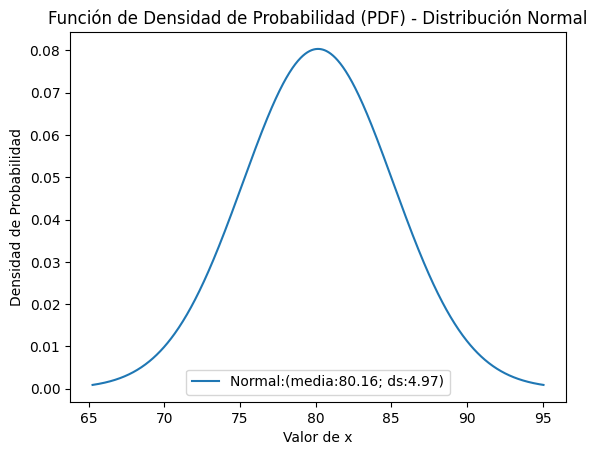

In [8]:
f_visualizar_dens_normal(num_aleatorios)

## Calcular probabilidades

Ahora bien con una densidad calculada de cada uno de los valores aleatrios generdos, ahora se puede calcular probabildia bajo un inetrvalo.

¿Cuál es la probabilidad de encontrar números entre 80 y 85?

$$
F(80 \le x \le 85)
$$

$$
F(x \le 85) - F(x \le 80)
$$

Se utiliza la función *norm.cdf()*, restando la probabilidad acumulada de 85 menos la probabilidad acumulada de 80.

In [9]:
x1 = 80
x2 = 85
probabilidad  = norm.cdf(x2, media, desv_std) - norm.cdf(x1, media, desv_std)
print ("La probabilidad entre ", x1, " y ", x2, " es", np.round(probabilidad, 4), "aproximadamnte ", np.round(probabilidad * 100, 2))

La probabilidad entre  80  y  85  es 0.348 aproximadamnte  34.8


## Visualizar probabildiades

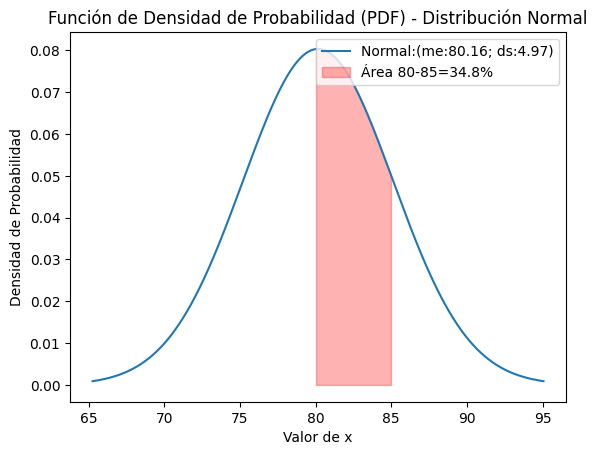

In [10]:
f_visualizar_dens_area_normal(num_aleatorios, x1, x2)

## Ejercicio estaturas pesos y generos de personas

Se carga un archivo con extensión *csv* que contiene medidas de personas. Las variables de interés son estatura en centímetros, peso en kilogramos y género que puede ser Hombre o Mujer.


### Cargar datos y análisis descriptivo

Se cargan datos y se presenta un análisis descriptivo de la cantidad de registros ,los estadísticos básicos de las variables estatura y peso así como la frecuencia por género.

Son $n=507$ registros de los cuales hay $260$ mujeres y $247$ hombres.

La media aritmética de la variable estatura es $171.14$ con desviación estándar de $9.40$; la media de la variable peso es $69.14$ con desviación estándar de $13.34$

     estatura  peso genero_cat
0       174.0  65.6     Hombre
1       175.3  71.8     Hombre
2       193.5  80.7     Hombre
3       186.5  72.6     Hombre
4       187.2  78.8     Hombre
..        ...   ...        ...
502     176.5  71.8      Mujer
503     164.4  55.5      Mujer
504     160.7  48.6      Mujer
505     174.0  66.4      Mujer
506     163.8  67.3      Mujer

[507 rows x 3 columns]
         estatura        peso
count  507.000000  507.000000
mean   171.143787   69.147535
std      9.407205   13.345762
min    147.200000   42.000000
25%    163.800000   58.400000
50%    170.300000   68.200000
75%    177.800000   78.850000
max    198.100000  116.400000
genero_cat
Mujer     260
Hombre    247
Name: count, dtype: int64


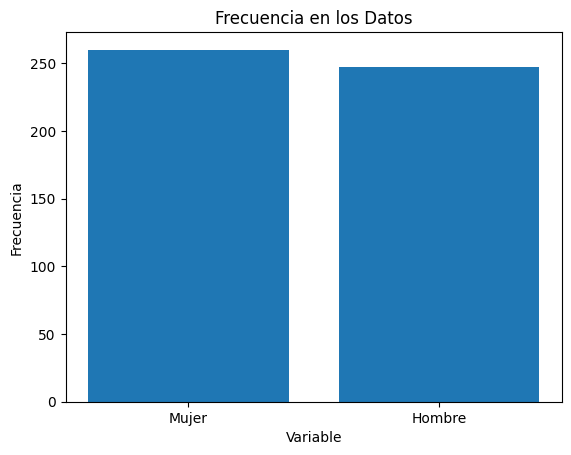

In [11]:
datos = pd.read_csv("https://raw.githubusercontent.com/rpizarrog/probabilidad-y-estad-stica/master/2023/datos/estatura%20peso%20generos.csv")
print(datos[['estatura', 'peso', 'genero_cat']])

print(datos[['estatura', 'peso']].describe())
# Determinar la frecuencia de cada atributo en la columna 'genero'
frecuencia_genero = datos['genero_cat'].value_counts()

# Imprimir la frecuencia
print(frecuencia_genero)

f_visualizar_frecuencia(frecuencia_genero)


### Valor esperado, varianza y desviación estándar

El valor esperado de una distribución  normal es igual a la media y la varianza es la propia varianza de los datos, así mismo la desvición es´tandra es la rai cuadrada de la varinza.



### Valor esperado

Si se elige a una persona aleatoriamente, ¿cuál será el valor esperado $VE$ de la estatura de la persona?, ¿cuánto puede variar la estatura con respeto al valor esperado $VE$?

El valor esperado es:  171.144  centímetros
En términos de varianza puede variar en: :  88.321
En términos de desvaición estándar puede variar en: :  9.3979  centímetros


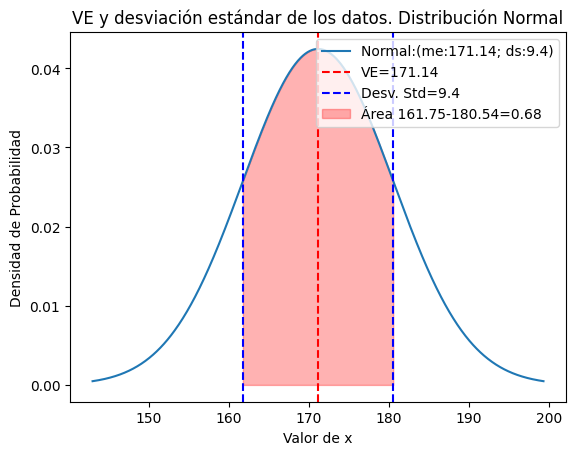

In [12]:
VE = np.mean(datos['estatura'])
print ("El valor esperado es: ", np.round(VE, 3), " centímetros")
varianza = np.var(datos['estatura'], )
print ("En términos de varianza puede variar en: : ", np.round(varianza, 4))
varianza = np.std(datos['estatura'], )
print ("En términos de desvaición estándar puede variar en: : ", np.round(varianza, 4), " centímetros")

f_visualizar_VE_desv_std_normal(datos['estatura'])

Hay un $68\%$ de probabilidad de seleccionar a una persona que tenga de estatura $171.14$ $\pm 9.4$ centímetros.

Se puede concluir en t´merios generales, que la mayoría de las personas tendrán una estatura alrededor de $171$ centímetros, y la mayoría de las diferencias estarán dentro de una desviación estándar de $9.4$ centímetros.

- El $68\%$ de los datos está entre $\mu \pm \sigma$.
- El $95\%$ de los datos está entre $\mu \pm 2 \cdot \sigma$.
- El $99\%$ de los datos está entre $\mu \pm 3 \cdot \sigma$.



### Probabilidades con datos del género hombres

#### ¿Cúal es la probabilidad de encontrar personas del género hombres con estatura mayor que 180 centímetros?



In [13]:
# Filtrar datos para obtener solo los hombres
 #datos_hombres = datos[datos['genero'] == 'Hombre']
datos_hombres = datos.query("genero_cat == 'Hombre'")
#print(datos_hombres['estatura'])
# Media estatura de hombres
media_est_hombres = np.mean(datos_hombres['estatura'])
desv_std_est_hombres = np.std(datos_hombres['estatura'])
print ("La media de estatura hombres", np.round(media_est_hombres, 4))
print ("La desviación estándar de estatura hombres", np.round(desv_std_est_hombres, 4))

La media de estatura hombres 177.7453
La desviación estándar de estatura hombres 7.1691


Con los estadístico de media y desviacón estándar y los valores, visualizar la densidad y el área de hombre con estatura maypr que $180$.

$$
F(x \ge 180)
$$

Restar:

$$
1 - F(x \le 180)
$$

para determinar los que están o son mayores que $180$.


La probabilidad entre  180  y  inf  es 0.3766 aproximadamente  37.66


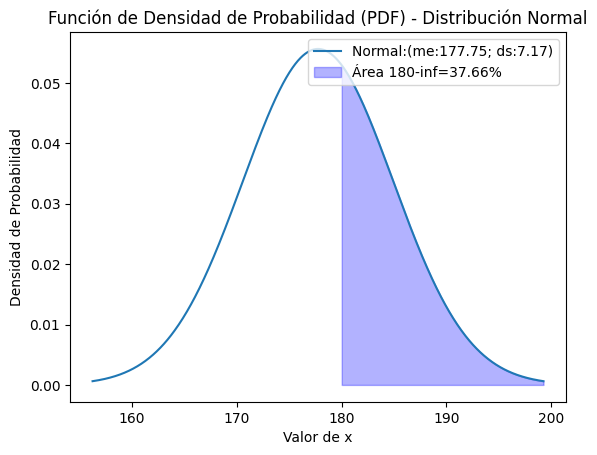

In [14]:
x1 = 180
x2 = np.inf
probabilidad  = 1 - norm.cdf(x1, media_est_hombres, desv_std_est_hombres)
print ("La probabilidad entre ", x1, " y ", x2, " es", np.round(probabilidad, 4), "aproximadamente ", np.round(probabilidad * 100, 2))
f_visualizar_dens_area_normal(datos_hombres['estatura'], x1, x2, v_color = 'blue')

#### ¿Cúal es la probabilidad de encontrar personas del género hombres con estatura entre 160 y 180 centímetros?

$$
F(160 \le x \le 180)
$$

Restar:

$$
F(x \le 180) - F(x \le 160)
$$

para determinar los que están en el intervalo $160$ - $180$

La probabilidad entre  160  y  180  es 0.6168 aproximadamente  61.68


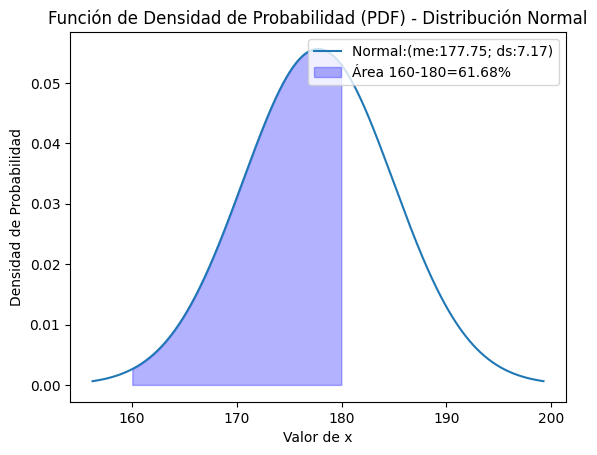

In [15]:
x1 = 160
x2 = 180
probabilidad  = norm.cdf(x2, media_est_hombres, desv_std_est_hombres) - norm.cdf(x1, media_est_hombres, desv_std_est_hombres)
print ("La probabilidad entre ", x1, " y ", x2, " es", np.round(probabilidad, 4), "aproximadamente ", np.round(probabilidad * 100, 2))
f_visualizar_dens_area_normal(datos_hombres['estatura'], x1, x2, v_color = 'blue')

#### ¿Cúal es la probabilidad de encontrar personas del género hombres con estatura menor o igual a 165 centímetros?

$$
F(x \le 165)
$$

para determinar los que están en el intervalo por debajo de $165$

La probabilidad entre  -inf  y  165  es 0.0377 aproximadamente  3.77


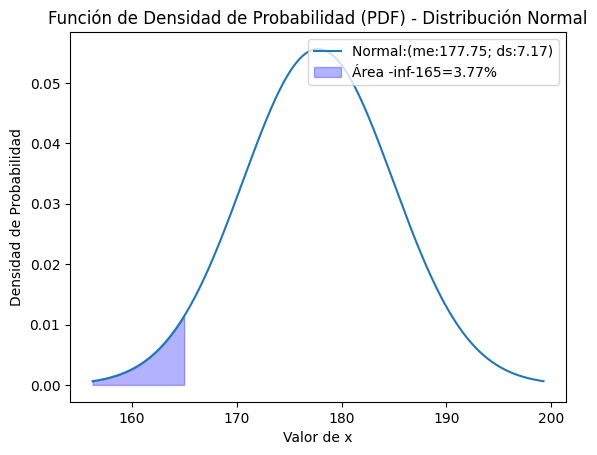

In [16]:
x1 = - np.inf
x2 = 165
probabilidad  = norm.cdf(x2, media_est_hombres, desv_std_est_hombres)
print ("La probabilidad entre ", x1, " y ", x2, " es", np.round(probabilidad, 4), "aproximadamente ", np.round(probabilidad * 100, 2))
f_visualizar_dens_area_normal(datos_hombres['estatura'], x1, x2, v_color = 'blue')

### Probabilidade con datos del género mujeres


#### ¿Cúal es la probabilidad de encontrar personas del género mujeres con estatura mayor que 180 centímetros?

In [17]:
# Filtrar datos para obtener solo las mujeres
datos_mujeres = datos.query("genero_cat == 'Mujer'")

# Media estatura de mujeres
media_est_mujeres = np.mean(datos_mujeres['estatura'])
desv_std_est_mujeres = np.std(datos_mujeres['estatura'])
print ("La media de estatura mujeres", np.round(media_est_mujeres, 4))
print ("La desviación estándar de estatura mujeres", np.round(desv_std_est_mujeres, 4))

La media de estatura mujeres 164.8723
La desviación estándar de estatura mujeres 6.532


Con los estadístico de media y desviacón estándar y los valores, visualizar la densidad y el área de la probabilidad con estatura mayr que $180$ en mujeres:

La probabilidad entre  180  y  inf  es 0.0103 aproximadamente  1.03


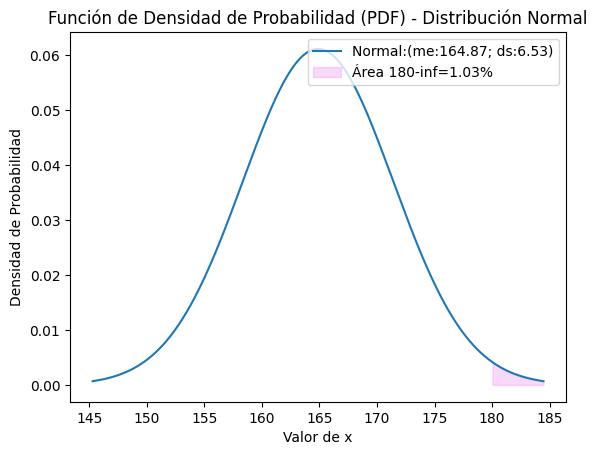

In [18]:
x1 = 180
x2 = np.inf
probabilidad  = 1 - norm.cdf(x1, media_est_mujeres, desv_std_est_mujeres)
print ("La probabilidad entre ", x1, " y ", x2, " es", np.round(probabilidad, 4), "aproximadamente ", np.round(probabilidad * 100, 2))
f_visualizar_dens_area_normal(datos_mujeres['estatura'], x1, x2, v_color = 'violet')

#### ¿Cúal es la probabilidad de encontrar personas del género mujeres con estatura entre 160 y 180 centímetros?



La probabilidad entre  160  y  180  es 0.7619 aproximadamente  76.19


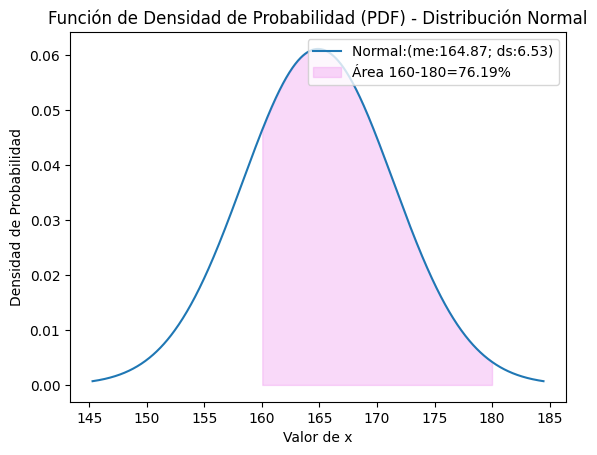

In [19]:
x1 = 160
x2 = 180
probabilidad  = norm.cdf(x2, media_est_mujeres, desv_std_est_mujeres) - norm.cdf(x1, media_est_mujeres, desv_std_est_mujeres)
print ("La probabilidad entre ", x1, " y ", x2, " es", np.round(probabilidad, 4), "aproximadamente ", np.round(probabilidad * 100, 2))
f_visualizar_dens_area_normal(datos_mujeres['estatura'], x1, x2, v_color = 'violet')

#### ¿Cúal es la probabilidad de encontrar personas del género hombres con estatura menor o igual a 165 centímetros?

La probabilidad entre  -inf  y  165  es 0.5078 aproximadamente  50.78


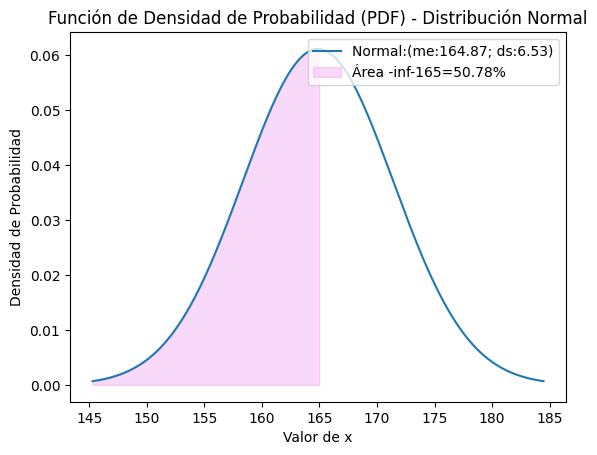

In [20]:
x1 = - np.inf
x2 = 165
probabilidad  = norm.cdf(x2, media_est_mujeres, desv_std_est_mujeres)
print ("La probabilidad entre ", x1, " y ", x2, " es", np.round(probabilidad, 4), "aproximadamente ", np.round(probabilidad * 100, 2))
f_visualizar_dens_area_normal(datos_mujeres['estatura'], x1, x2, v_color = 'violet')

### Con respecto al peso de las personas hombre y mujeres

- ¿cuál es el valor esperado $VE$ si se selecciona a una persona al azar con respecto al peso corporal, independientemente si es hombre o mujer?
- ¿cuál es la varianza del peso corporal de las personas?
- ¿cuál será la desviación estándar con respeco al peso corporal, independientemente si es hombre o mujer ?


####  Con repecto al peso en kilogramos de los hombres

- ¿Cuál es la probabilidad de encontrar hombres con un peso coporal superior a $80$ kilogramos; $1 - F(x \le 80)$
- ¿Cual es la probabilidad de encontrar hombres con un peso corporal entre $70$ y $75$ kilogramos?; $F(70 \le x \le 75)$
- ¿Cuál es la probabilidad de encontrar hombres que pesen menos de $65$ kilogramos?; $F(x \le 65)$

####  Con repecto al peso en kilogramos de las mujeres

- ¿Cuál es la probabilidad de encontrar mujeres con un peso coporal superior a $80$ kilogramos; $1 - F(x \le 80)$
- ¿Cual es la probabilidad de encontrar mujeres con un peso corporal entre $70$ y $75$ kilogramos?; $F(70 \le x \le 75)$
- ¿Cuál es la probabilidad de encontrar mujeres que pesen menos de $65$ kilogramos?; $F(x \le 65)$



### Peso de las personas (hombres y mujeres juntos)

Valor esperado, varianza y desviación estándar del peso.

El valor esperado del peso es:  69.1475  kilogramos
La varianza del peso es:  177.7581
La desviación estándar del peso es:  13.3326  kilogramos


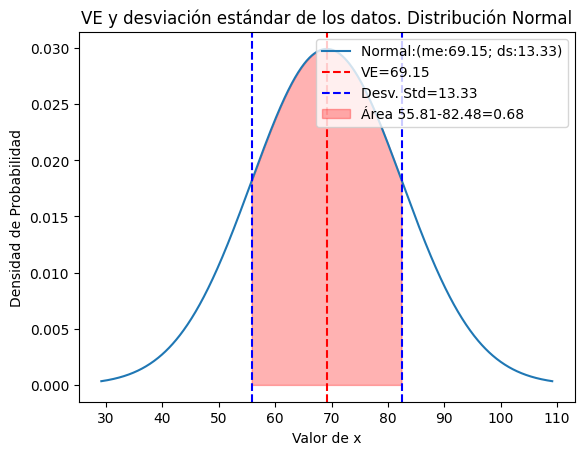

In [21]:
VE = np.mean(datos['peso'])
print ("El valor esperado del peso es: ", np.round(VE, 4), " kilogramos")
varianza = np.var(datos['peso'])
print ("La varianza del peso es: ", np.round(varianza, 4))
desv_std = np.std(datos['peso'])
print ("La desviación estándar del peso es: ", np.round(desv_std, 4), " kilogramos")

f_visualizar_VE_desv_std_normal(datos['peso'])

### Peso de los hombres

- $1 - F(x \le 80)$
- $F(70 \le x \le 75)$
- $F(x \le 65)$

La media de peso hombres 78.1445
La desviación estándar de peso hombres 10.4916
La probabilidad entre  80  y  inf  es 0.4298 aproximadamente  42.98


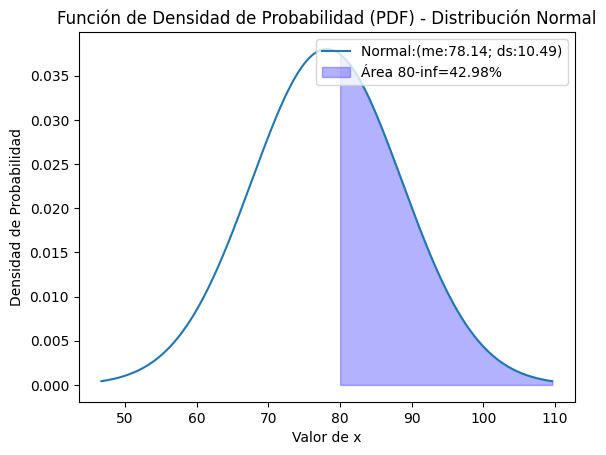

La probabilidad entre  70  y  75  es 0.1634 aproximadamente  16.34


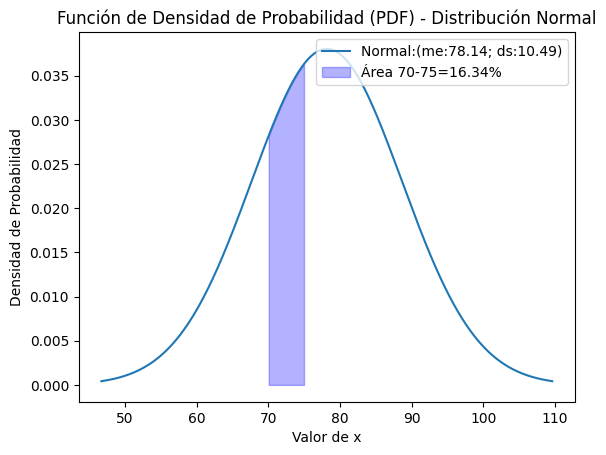

La probabilidad entre  -inf  y  65  es 0.1051 aproximadamente  10.51


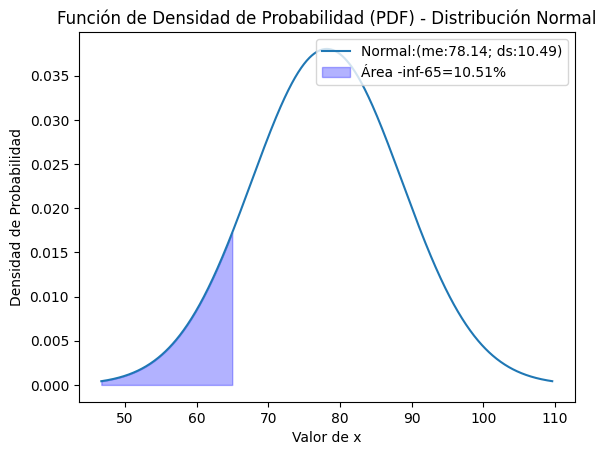

In [22]:
datos_hombres = datos.query("genero_cat == 'Hombre'")
media_peso_hombres = np.mean(datos_hombres['peso'])
desv_std_peso_hombres = np.std(datos_hombres['peso'])
print ("La media de peso hombres", np.round(media_peso_hombres, 4))
print ("La desviación estándar de peso hombres", np.round(desv_std_peso_hombres, 4))

# Peso superior a 80 kg
x1 = 80
x2 = np.inf
probabilidad = 1 - norm.cdf(x1, media_peso_hombres, desv_std_peso_hombres)
print ("La probabilidad entre ", x1, " y ", x2, " es", np.round(probabilidad, 4), "aproximadamente ", np.round(probabilidad * 100, 2))
f_visualizar_dens_area_normal(datos_hombres['peso'], x1, x2, v_color = 'blue')

# Peso entre 70 y 75 kg
x1 = 70
x2 = 75
probabilidad = norm.cdf(x2, media_peso_hombres, desv_std_peso_hombres) - norm.cdf(x1, media_peso_hombres, desv_std_peso_hombres)
print ("La probabilidad entre ", x1, " y ", x2, " es", np.round(probabilidad, 4), "aproximadamente ", np.round(probabilidad * 100, 2))
f_visualizar_dens_area_normal(datos_hombres['peso'], x1, x2, v_color = 'blue')

# Peso menor a 65 kg
x1 = -np.inf
x2 = 65
probabilidad = norm.cdf(x2, media_peso_hombres, desv_std_peso_hombres)
print ("La probabilidad entre ", x1, " y ", x2, " es", np.round(probabilidad, 4), "aproximadamente ", np.round(probabilidad * 100, 2))
f_visualizar_dens_area_normal(datos_hombres['peso'], x1, x2, v_color = 'blue')

### Peso de las mujeres

- $1 - F(x \le 80)$
- $F(70 \le x \le 75)$
- $F(x \le 65)$

La media de peso mujeres 60.6004
La desviación estándar de peso mujeres 9.5972
La probabilidad entre  80  y  inf  es 0.0216 aproximadamente  2.16


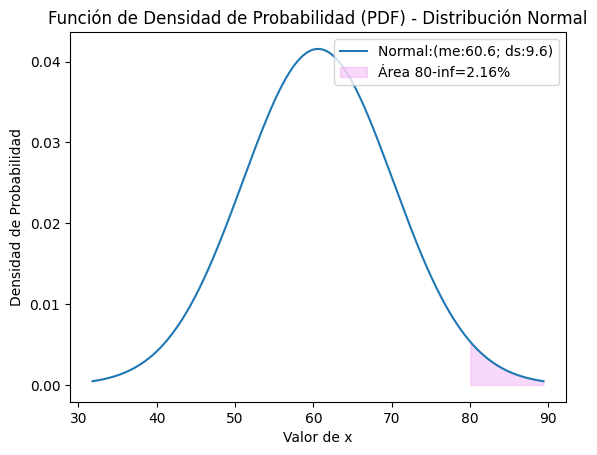

La probabilidad entre  70  y  75  es 0.0969 aproximadamente  9.69


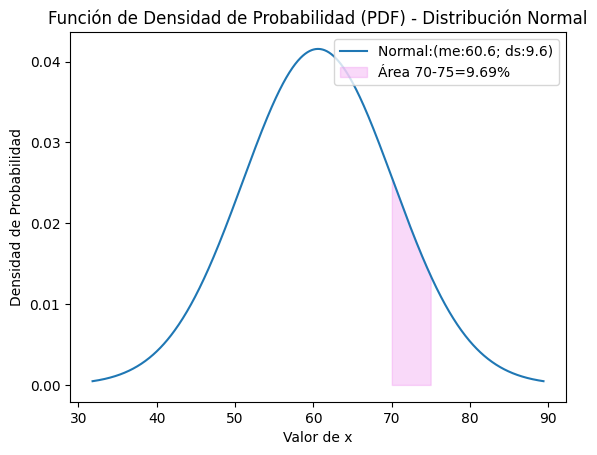

La probabilidad entre  -inf  y  65  es 0.6767 aproximadamente  67.67


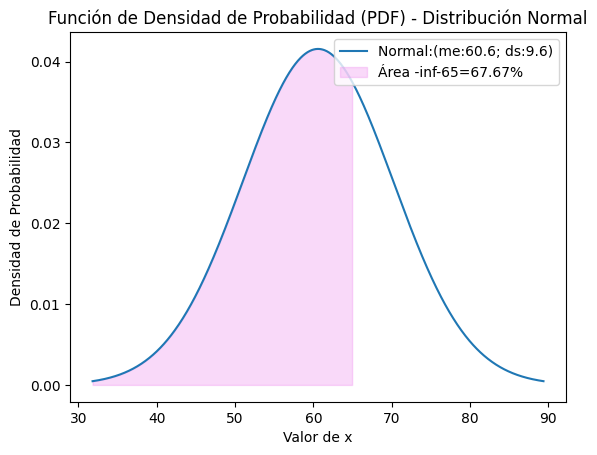

In [23]:
datos_mujeres = datos.query("genero_cat == 'Mujer'")
media_peso_mujeres = np.mean(datos_mujeres['peso'])
desv_std_peso_mujeres = np.std(datos_mujeres['peso'])
print ("La media de peso mujeres", np.round(media_peso_mujeres, 4))
print ("La desviación estándar de peso mujeres", np.round(desv_std_peso_mujeres, 4))

# Peso superior a 80 kg
x1 = 80
x2 = np.inf
probabilidad = 1 - norm.cdf(x1, media_peso_mujeres, desv_std_peso_mujeres)
print ("La probabilidad entre ", x1, " y ", x2, " es", np.round(probabilidad, 4), "aproximadamente ", np.round(probabilidad * 100, 2))
f_visualizar_dens_area_normal(datos_mujeres['peso'], x1, x2, v_color = 'violet')

# Peso entre 70 y 75 kg
x1 = 70
x2 = 75
probabilidad = norm.cdf(x2, media_peso_mujeres, desv_std_peso_mujeres) - norm.cdf(x1, media_peso_mujeres, desv_std_peso_mujeres)
print ("La probabilidad entre ", x1, " y ", x2, " es", np.round(probabilidad, 4), "aproximadamente ", np.round(probabilidad * 100, 2))
f_visualizar_dens_area_normal(datos_mujeres['peso'], x1, x2, v_color = 'violet')

# Peso menor a 65 kg
x1 = -np.inf
x2 = 65
probabilidad = norm.cdf(x2, media_peso_mujeres, desv_std_peso_mujeres)
print ("La probabilidad entre ", x1, " y ", x2, " es", np.round(probabilidad, 4), "aproximadamente ", np.round(probabilidad * 100, 2))
f_visualizar_dens_area_normal(datos_mujeres['peso'], x1, x2, v_color = 'violet')

## Tiempo de duración de focos

Una empresa de material eléctrico fabrica focos de luz que tienen una duración, antes de quemarse (fundirse), que se distribuye *normalmente* con media igual a $\mu = 800$ horas y una desviación estándar de $\sigma = 40$ horas. Ejercicio extraído de [@walpole_probabilidad_2012].

Encuentre las siguientes probabilidades:

- ¿cuál es la probabilidad de que un foco se queme entre 778 y 834 horas?; $F(778 \le x \le 834)$.
- ¿cuál es la probabilidad de que un foco se queme a más de 850 horas?; $1 - F(x \le 850)$
- ¿cuál es el valor esperado $VE$ y la desviación estándar y qué significan para este contexto?

### Inicializar variables

In [24]:
# Inicializar variables
np.random.seed(2023)  # para que salgan siempre los mismos números
media = 800
desv_std = 40

# Se generan datos aleatorios con media y desviacin estándar similar
datos = norm.rvs(loc = media, scale = desv_std, size = 100)
print ("Los datos")
print(np.round(datos, 4))

print()
media = np.mean(datos)
desv_std = np.std(datos)

print ("La media de los datos es", np.round(media, 2))
print ("La desviación estándar de los datos es: ", np.round(desv_std, 2))


Los datos
[828.4669 787.0206 759.9252 809.45   795.9136 754.3483 906.1763 857.6242
 803.9561 675.1387 756.9391 786.9727 758.5801 782.9472 758.8255 779.129
 783.0897 796.0302 744.7897 812.0761 758.656  739.9129 744.8163 791.8218
 825.685  792.753  830.87   829.6609 852.9905 817.5715 777.6851 837.0832
 775.9709 739.2101 883.8932 835.7025 863.8595 774.4495 754.6781 826.2639
 823.8315 767.5552 787.9786 840.3356 756.4895 728.5168 813.6248 749.8599
 814.8315 818.2102 708.6512 799.9671 895.955  696.6758 852.4404 736.8209
 766.3727 793.3796 717.2636 818.1095 802.0453 790.4776 791.6796 816.0522
 807.3268 849.4332 788.328  801.1997 765.2638 824.1739 829.1422 854.5928
 853.7078 741.7317 838.7743 801.4615 897.2729 816.9039 873.7569 791.1375
 813.4847 777.7128 802.1257 842.1521 773.6594 873.7779 796.9794 810.5705
 744.1856 828.3366 830.5102 814.6918 776.9269 783.3598 794.4983 851.7995
 820.8236 792.2291 784.5763 677.3686]

La media de los datos es 798.02
La desviación estándar de los datos es:  44.

 ### probabilidad de que un foco se queme entre 778 y 834 horas?;  F(778≤x≤834) .


La probabilidad entre  778  y  834  es 0.4603 aproximadamente  46.03


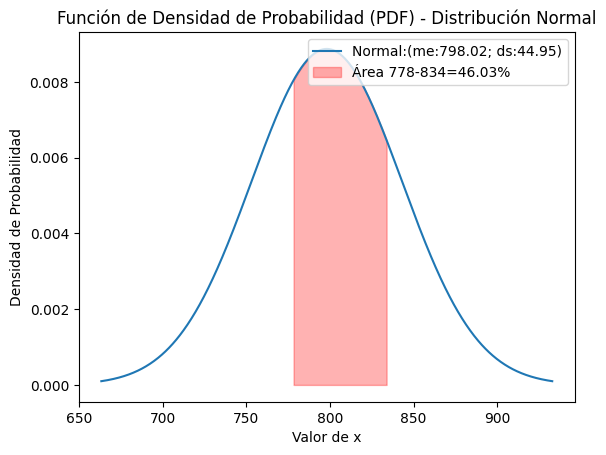

In [25]:
# El intervalo
x1 = 778
x2 = 834

# La probabilidad
probabilidad  = norm.cdf(x2, media, desv_std) - norm.cdf(x1, media, desv_std)
print ("La probabilidad entre ", x1, " y ", x2, " es", np.round(probabilidad, 4), "aproximadamente ", np.round(probabilidad * 100, 2))
f_visualizar_dens_area_normal(datos, x1, x2, v_color = 'red')

### Probabilidad de que un foco se queme a más de 850 horas?;  1−F(x≤850)

La probabilidad entre  850  y  inf  es 0.1238 aproximadamente  12.38


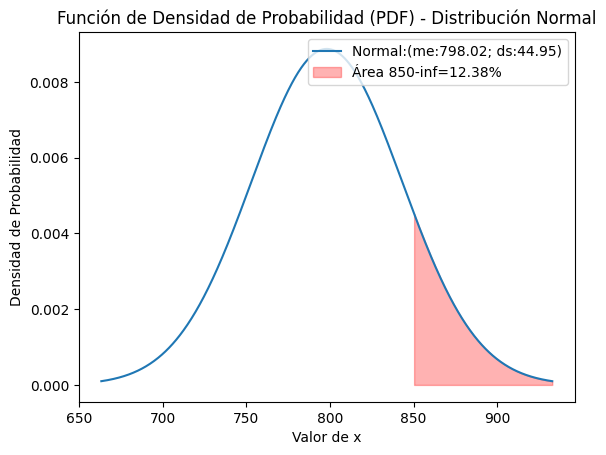

In [26]:
## El intervalo
x1 = 850
x2 = np.inf

# La probabilidad
probabilidad  = 1 - norm.cdf(x1, media, desv_std)
print ("La probabilidad entre ", x1, " y ", x2, " es", np.round(probabilidad, 4), "aproximadamente ", np.round(probabilidad * 100, 2))
f_visualizar_dens_area_normal(datos, x1, x2, v_color = 'red')

### Valor esperado y desviación estándar de los focos

El valor esperado VE (con los datos generados) es:  798.02  horas
La desviación estándar (con los datos generados) es:  44.95  horas

Con los parámetros del enunciado (mu = 800, sigma = 40):
F(778 <= x <= 834) =  0.5112
1 - F(x <= 850) =  0.1056


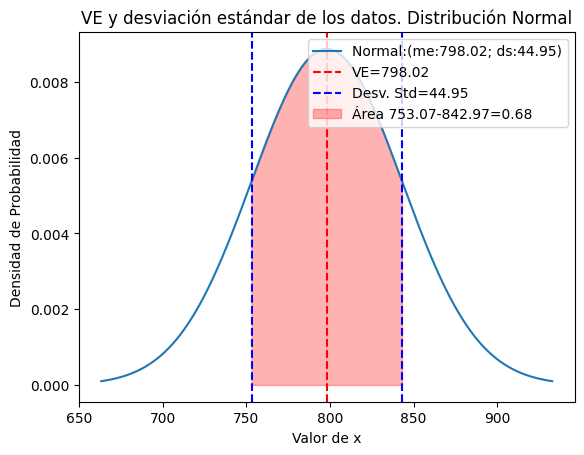

In [27]:
print ("El valor esperado VE (con los datos generados) es: ", np.round(media, 2), " horas")
print ("La desviación estándar (con los datos generados) es: ", np.round(desv_std, 2), " horas")

# Con los parámetros que da el enunciado (mu = 800, sigma = 40)
print()
print ("Con los parámetros del enunciado (mu = 800, sigma = 40):")
print ("F(778 <= x <= 834) = ", np.round(norm.cdf(834, 800, 40) - norm.cdf(778, 800, 40), 4))
print ("1 - F(x <= 850) = ", np.round(1 - norm.cdf(850, 800, 40), 4))

f_visualizar_VE_desv_std_normal(datos)

# Eercicio de los sueldos

Los sueldos mensuales en una empresa siguen una distribución *normal* con media de *16000* pesos, y desviación estándar de 1000 pesos.

- ¿qué porcentaje de trabajadores ganan entre 10000 y 15000 pesos?; $F(10000\le x \le 15000)$
- ¿qué porcentaje de trabajadores ganan menos de 8500 pesos ?; $F(x \le 8500)$
- ¿qué porcentaje de trabajadores ganan más de 10000 pesos; $1 - F(x \le 10000)$ ?
- ¿qué significado tiene el valor esperado y la desviación estándar en este contexto?

### Inicializar variables y calcular porcentajes

In [28]:
media = 16000
desv_std = 1000

# F(10000 <= x <= 15000)
p1 = norm.cdf(15000, media, desv_std) - norm.cdf(10000, media, desv_std)
print ("Entre 10000 y 15000 pesos: ", np.round(p1, 4), " aproximadamente ", np.round(p1 * 100, 2), "%")

# F(x <= 8500)
p2 = norm.cdf(8500, media, desv_std)
print ("Menos de 8500 pesos: ", p2, " aproximadamente ", np.round(p2 * 100, 2), "%")

# 1 - F(x <= 10000)
p3 = 1 - norm.cdf(10000, media, desv_std)
print ("Más de 10000 pesos: ", np.round(p3, 6), " aproximadamente ", np.round(p3 * 100, 2), "%")

Entre 10000 y 15000 pesos:  0.1587  aproximadamente  15.87 %
Menos de 8500 pesos:  3.1908916729108844e-14  aproximadamente  0.0 %
Más de 10000 pesos:  1.0  aproximadamente  100.0 %


## Ejercicio de edades de estudiantes

Un conjunto de estudiante se les pide la edad, se calcula la media y la desviación estándar y se calculan probabilidades.





### Incicializar datos


In [29]:
datos = [18, 19, 20, 21, 22, 23, 19, 18, 19, 20,
         21, 22, 19, 19, 18, 17, 19, 20, 21, 22, 23, 19, 18, 20]

media = np.mean(datos)
desv_std = np.std(datos)

print ("La media de la edad es: ", np.round(media, 2))
print ("La desviación estándar de los datos es :", np.round(desv_std, 2))

La media de la edad es:  19.88
La desviación estándar de los datos es : 1.64


### Densidades
¿Cual es el valor de la densidad para valores en $\text {x de 18, 21 y 19.87}$?

- Densidad para $f(x=18)$
- Densidad para $f(x=21)$
- Densidad para $f(x=19.87)$


In [30]:
densidad = f_x_normal(18, media, desv_std)
print ("La la densidadad para valores de x =", 18 ," es ", np.round(densidad, 4))
densidad = f_x_normal(21, media, desv_std)
print ("La la densidadad para valores de x =", 21 ," es ", np.round(densidad, 4))
densidad = f_x_normal(19.87, media, desv_std)
print ("La la densidadad para valores de x =", 19.87 ," es ", np.round(densidad, 4))
densidad = f_x_normal(np.inf, media, desv_std)
print ("La la densidadad para valores de x =", np.inf ," es ", np.round(densidad, 4))

La la densidadad para valores de x = 18  es  0.1266
La la densidadad para valores de x = 21  es  0.1922
La la densidadad para valores de x = 19.87  es  0.2431
La la densidadad para valores de x = inf  es  0.0


### Visualizar la densidad de los datos


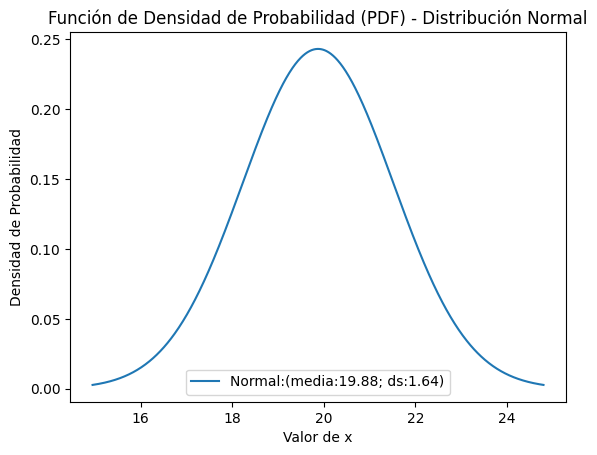

In [31]:
f_visualizar_dens_normal(datos)

#### Probabilidad F(18 ≤  x ≤ 20 )

¿Cual es la  probabilida de elegir aleatoriamente una persona que tenga edad entre $18$ y $20$ años.




La probabilidad entre  18  y  20  es 0.4038 aproximadamente  40.38


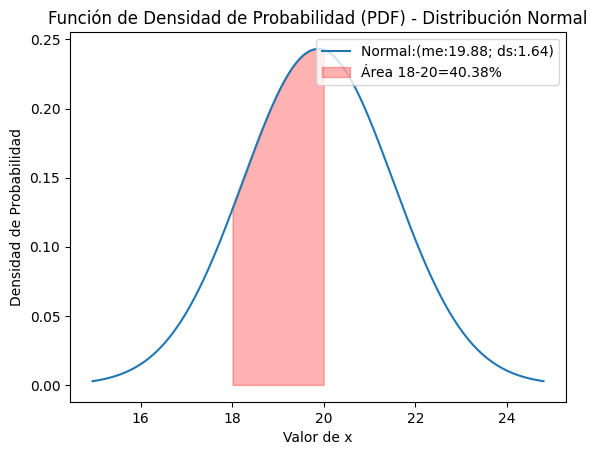

In [32]:
## El intervalo
x1 = 18
x2 = 20

# La probabilidad
probabilidad  = norm.cdf(x2, media, desv_std) - norm.cdf(x1, media, desv_std)
print ("La probabilidad entre ", x1, " y ", x2, " es", np.round(probabilidad, 4), "aproximadamente ", np.round(probabilidad * 100, 2))
f_visualizar_dens_area_normal(datos, x1, x2, v_color = 'red')


¿Cual es la  probabilida de elegir aleatoriamente una persona que tenga edad entre $18$ y $20$ años.
#### Probabilidad F(x ≥ 19.87 )

La probabilidad entre  19.875  y  inf  es 0.5 aproximadamente  50.0


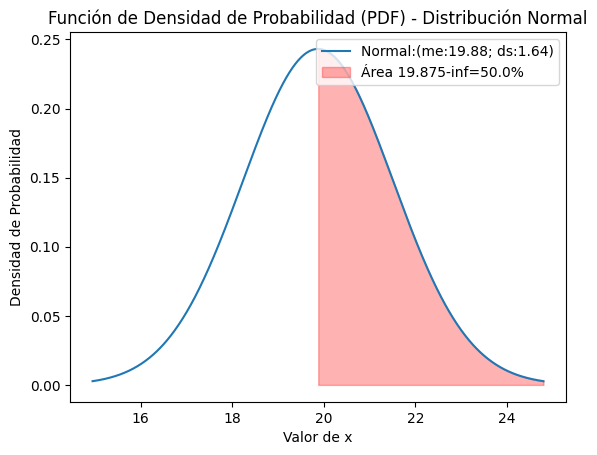

In [33]:
## El intervalo
x1 = media
x2 = np.inf

# La probabilidad
probabilidad  = 1 - norm.cdf(x1, media, desv_std)
print ("La probabilidad entre ", x1, " y ", x2, " es", np.round(probabilidad, 4), "aproximadamente ", np.round(probabilidad * 100, 2))
f_visualizar_dens_area_normal(datos, x1, x2, v_color = 'red')

### Densidades para x = 16, 19 y 24

Y la probabilidad de encontrar alumnos entre 20 y 25 años, $F(20 \le x \le 25)$.

La densidad para x = 16  es  0.015
La densidad para x = 19  es  0.2109
La densidad para x = 24  es  0.0103
La probabilidad entre  20  y  25  es 0.4687 aproximadamente  46.87


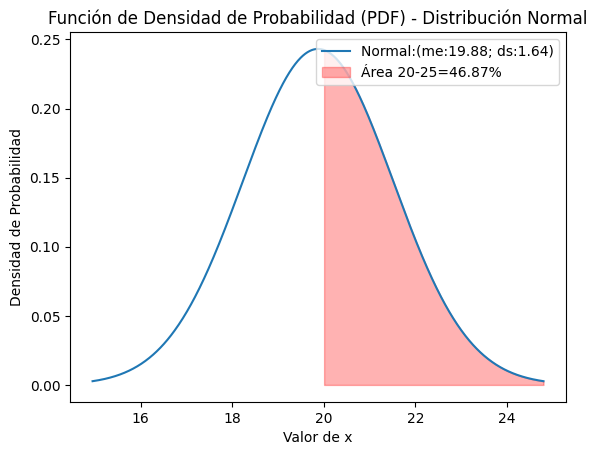

In [34]:
for x in (16, 19, 24):
  densidad = f_x_normal(x, media, desv_std)
  print ("La densidad para x =", x, " es ", np.round(densidad, 4))

x1 = 20
x2 = 25
probabilidad  = norm.cdf(x2, media, desv_std) - norm.cdf(x1, media, desv_std)
print ("La probabilidad entre ", x1, " y ", x2, " es", np.round(probabilidad, 4), "aproximadamente ", np.round(probabilidad * 100, 2))
f_visualizar_dens_area_normal(datos, x1, x2, v_color = 'red')

## Tiempo dedicado a celular

Se hizo un estudio sobre el tiempo dedicado al uso del celular en $n=350$ estudiantes de educación superior. El estudio arroja que el tiempo promedio ees de $\mu = 4.5$ hrs. con una desviación estándar de $\sigma = 1.4$ hrs.

* Calcular la densidad para valores de x = 3, 5, 7 u 9.
* Representar la gráfica de gauss
* Calcular la probabilidad que en una nueva encuesta, los alumnos digan que usan el celular entre 3 y 4.5 horas. $f(3 \le x \le 4.5)$
* Calcular la probabilidad que en una nueva encuesta, los alumnos digan que usan el celular entre 6 y 7 horas. $f(3 \le x \le 4.5)$




### Calcular las densidades
$$
f(x) =\frac{1}{\sigma \cdot \sqrt{2 \cdot \pi}}\cdot e
^{\frac{-1}{2}\cdot ( \frac {x - \mu}{\sigma}) ^2}
$$


### inicializar valores

In [35]:
media = 4.5
desv_std = 1.4



In [36]:
# Calcular las densidades
x= 3
print ("Densidad de ", x, " = ", f_x_normal(x, media, desv_std))

x= 5
print ("Densidad de ", x, " = ", f_x_normal(x, media, desv_std))

x= 7
print ("Densidad de ", x, " = ", f_x_normal(x, media, desv_std))

x= 9
print ("Densidad de ", x, " = ", f_x_normal(x, media, desv_std))

Densidad de  3  =  0.16051139185154825
Densidad de  5  =  0.26735276376026396
Densidad de  7  =  0.05785597623764886
Densidad de  9  =  0.0016266589423423465


### Representar la gráfica de gauss


[3.5645 4.5798 3.2269 2.4169 6.1375 5.0511 5.2428 3.679  5.9791 3.4725
 4.3824 4.6782 4.9822 5.4604 5.0599 5.7508 5.0387 5.3976 3.6918 3.3521
 5.5455 7.0715 2.4623 3.3398 3.6472 3.0002 2.8383 3.7431 3.6061 4.7106
 5.7872 5.7742 6.7473 5.434  5.8305 5.5281 5.9217 5.3783 5.9877 4.868
 1.5789 2.9931 3.7895 4.1157 7.0883 3.5221 3.4047 2.7972 6.4973 5.9948
 4.6221 1.4292 6.6418 3.7211 5.1218 3.5452 1.5888 4.7678 3.2106 4.6928
 5.2127 4.7847 3.6146 4.0023 5.14   5.6467 7.2035 4.7266 5.9417 4.2358
 3.5369 4.8659 3.0497 3.0254 3.4049 4.0228 3.9863 8.1249 4.0662 3.6646
 3.5845 4.7727 5.2363 3.3249 5.0388 8.0604 2.1496 4.8454 5.6058 6.921
 2.9495 4.7537 4.6789 3.0074 6.3153 4.8801 6.0588 2.0604 3.624  4.875
 5.801  5.8823 4.2071 5.8688 5.469  3.032  4.6124 5.1862 3.4852 2.8277
 6.5385 6.0115 6.4169 6.1298 2.415  7.3661 2.1961 6.419  6.2047 4.9611
 7.3195 4.3915 2.3299 4.5471 6.1376 3.5923 4.8483 3.345  5.0644 4.6903
 3.6526 4.9413 6.4171 3.7361 1.9263 5.7664 6.7223 2.6183 7.6873 4.268
 4.8197 5.

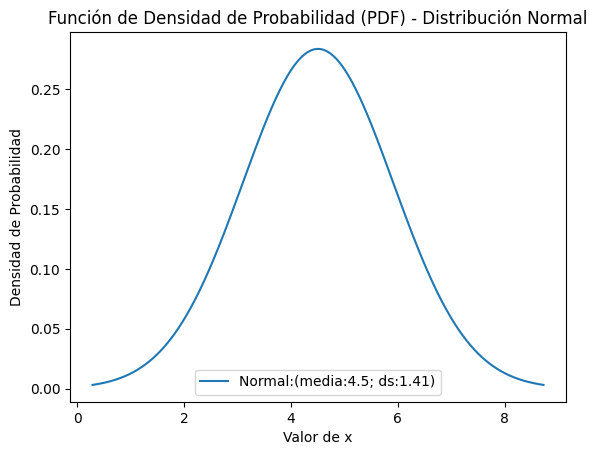

In [37]:
# Generar 350 números aleatorios de una distribución normal con media 0 y desviación estándar 1
n = 350
tiempos = np.random.normal(4.5, 1.4, n)
print(np.round(tiempos, 4))
f_visualizar_dens_normal(tiempos)

### Calcualar la probabilidad de que un estudiante use el teléfono entre 3 y 4.5 horas

$$
$f(3 \le x \le 4.5)$
$$

La probabilidad se estima con los datos de los tiempos generados aleatoriamente, por lo que la media y desviación puede cambiar y no ser eactamente 4.5 y 1.4 respectivamente.


La probabilidad entre  3  y  4.5  es 0.358 aproximadamente  35.8


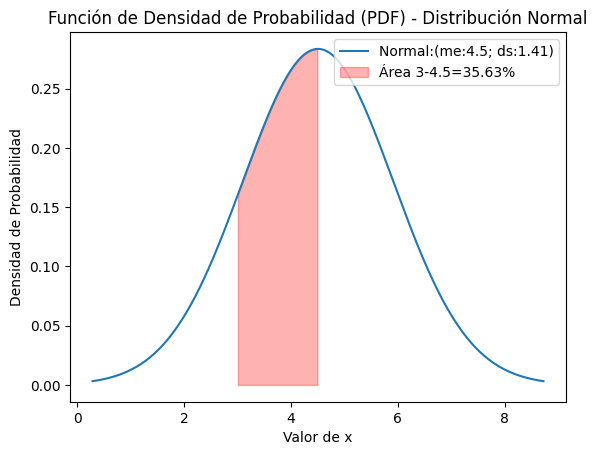

In [38]:
## El intervalo
datos = tiempos
x1 = 3
x2 = 4.5

# La probabilidad
probabilidad  = norm.cdf(x2, media, desv_std) - norm.cdf(x1, media, desv_std)
print ("La probabilidad entre ", x1, " y ", x2, " es", np.round(probabilidad, 4), "aproximadamente ", np.round(probabilidad * 100, 2))
f_visualizar_dens_area_normal(datos, x1, x2, v_color = 'red')

### Calcualar la probabilidad de que un estudiante use el teléfono entre 6 y 7 horas

$$
$f(6 \le x \le 6)$
$$

La probabilidad entre  6  y  7  es 0.1049 aproximadamente  10.49


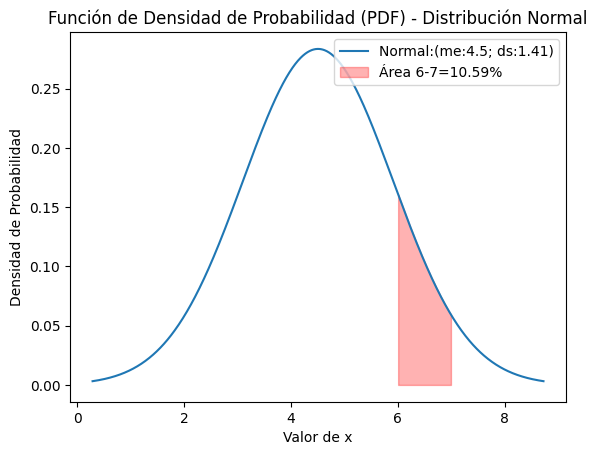

In [39]:
## El intervalo
datos = tiempos
x1 = 6
x2 = 7

# La probabilidad
probabilidad  = norm.cdf(x2, media, desv_std) - norm.cdf(x1, media, desv_std)
print ("La probabilidad entre ", x1, " y ", x2, " es", np.round(probabilidad, 4), "aproximadamente ", np.round(probabilidad * 100, 2))
f_visualizar_dens_area_normal(datos, x1, x2, v_color = 'red')

# Interpretación del caso

Con los datos de estatura y peso corporal de personas cargados en el caso:

- ¿Qué es más probable: encontrar hombres que midan por encima de $180$ centímetros o mujeres por encima de $180$ centímetros? **Resp**: Existe una probabilidad del $37.66$% de encontrar hombres con estatura superior a 180 centímetros, contra $1.03$% de encontrar mujeres. Es más probable encontrar hombres.

- ¿Qué es más probable: encontrar hombres que midan $165$ centímetros o menos o mujeres que midan $165$ centímetros o menos? **Resp**: Es más probable encontrar mujeres, con $50.78$% aproximadamente, contra $3.77$% de los hombres.

Las probabilidades se calcularon con los datos cargados.

**Peso corporal de las personas**

- El valor esperado del peso de una persona al azar (hombres y mujeres juntos) es $VE = 69.1475$ kg.
- La varianza es $177.7581$ y la desviación estándar es $13.3326$ kg. O sea que el peso puede variar como 13 kg de más o de menos.
- ¿Qué es más probable, hombres con peso superior a $80$ kg o mujeres con peso superior a $80$ kg? Hombres: $42.98$% contra mujeres: $2.16$%. Es más probable encontrar hombres.
- ¿Qué es más probable, hombres con peso menor a $65$ kg o mujeres con peso menor a $65$ kg? Hombres: $10.51$% contra mujeres: $67.67$%. Es más probable encontrar mujeres.
- Entre $70$ y $75$ kg: hombres $16.34$% y mujeres $9.69$%.

**Duración de los focos ($\mu = 800$ horas, $\sigma = 40$ horas)**

- La probabilidad de que un foco se queme entre 778 y 834 horas es $0.4603$, o sea 46.03% con los datos generados en el notebook. Con los parámetros exactos del enunciado ($\mu = 800$, $\sigma = 40$) sale $0.5112$, o sea 51.12%.
- La probabilidad de que un foco se queme a más de 850 horas es $0.1238$, o sea 12.38% con los datos generados. Con los parámetros del enunciado sale $0.1056$, o sea 10.56%.
- Los valores salen un poco distintos porque los datos generados son una muestra de 100 y su media ($798.02$) y desviación ($44.95$) no son exactamente 800 y 40.
- El valor esperado significa que un foco dura en promedio unas 800 horas antes de quemarse. La desviación estándar de 40 horas significa que la duración puede variar como 40 horas de más o de menos; la mayoría de los focos (68%) dura entre 760 y 840 horas.

**Sueldos ($\mu = 16000$ pesos, $\sigma = 1000$ pesos)**

- Entre 10000 y 15000 pesos gana el $15.87$% de los trabajadores.
- Menos de 8500 pesos gana prácticamente el $0$% (la probabilidad es casi cero porque 8500 está como 7.5 desviaciones por debajo de la media).
- Más de 10000 pesos gana prácticamente el $100$% de los trabajadores.
- El valor esperado significa que el sueldo típico es de 16000 pesos al mes. La desviación estándar significa que los sueldos varían como 1000 pesos de más o de menos; la mayoría (68%) gana entre 15000 y 17000 pesos.

**Edades de los estudiantes ($\mu = 19.875$, $\sigma = 1.6409$)**

- Densidad para $x=16$: $0.0150$; para $x=19$: $0.2109$; para $x=24$: $0.0103$. La densidad es más alta cerca de la media (19) y baja hacia los extremos.
- La probabilidad de encontrar alumnos entre 20 y 25 años es $0.4687$, o sea 46.87%.

**Tiempo dedicado al celular ($\mu = 4.5$ horas, $\sigma = 1.4$ horas)**

- Densidades: $f(3) = 0.1605$, $f(5) = 0.2674$, $f(7) = 0.0579$ y $f(9) = 0.0016$. Entre más lejos de 4.5 horas, más baja la densidad.
- La probabilidad de que usen el celular entre 3 y 4.5 horas es $0.3580$, o sea 35.8%.
- La probabilidad de que lo usen entre 6 y 7 horas es $0.1049$, o sea 10.49%.


# Bibliografía

- UC3M. n.d. “Introducción a La Estadística y Probabilidad.” http://halweb.uc3m.es/esp/Personal/personas/mwiper/docencia/Spanish/Introduction_to_Statistics/intro_continuous2.pdf.

- Walpole, Ronald E., Raymond H. Myers, and Sharon L. Myers. 2012. Probabilidad y Estadística Para Ingeniería y Ciencias. Novena Edición. México: Pearson.